## Global sensitivity analysis of the spinning dust SED features to the grain and environmental parameters.

In [1]:
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import matplotlib.patches as mpatches
from matplotlib.colors import to_rgba
import warnings
warnings.filterwarnings('ignore')

# Add the root directory of the package to sys.path
sys.path.append('/Users/zzhang/Workspace/SpyDust/')
sys.path.append('../')

In [2]:
# Configure matplotlib for publication quality
plt.rcParams.update({
    'font.size': 12,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif', 'Bitstream Vera Serif', 'serif'],
    'text.usetex': False,  # Set to True if LaTeX is available
    'figure.figsize': [10, 8],
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.format': 'pdf',
    'axes.linewidth': 1.2,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'lines.linewidth': 2,
    'lines.markersize': 6
})

In [3]:
# Check which font is actually being used
import matplotlib.font_manager as fm
font_prop = fm.FontProperties(family='serif')
print(f"Active serif font: {font_prop.get_name()}")
print(f"Available serif fonts: {[f.name for f in fm.fontManager.ttflist if 'serif' in f.name.lower()][:5]}")  # Show first 5

Active serif font: Times New Roman
Available serif fonts: ['DejaVu Serif', 'DejaVu Serif', 'DejaVu Serif', 'DejaVu Serif Display', 'DejaVu Serif']


In [4]:
# Import SpyDust modules
import functools
import SpyDust.Grain as Grain
from SpyDust.SpyDust import SpyDust_given_grain_size_shape
from SpyDust.util import makelogtab, cgsconst
from SpyDust.SPDUST_as_is import emissivity
import matplotlib.cm as cm


l_a computed
readPAH computed
Loaded previously computed Jpeisrf arrays from file.
Tev table already exists at /Users/zzhang/Workspace/SpyDust/SpyDust/Data_Files/Tev_30a_30chi.txt.
I(Zg<0, parabolic) stored
I(rot, e, Zg <> 0) stored
I(Zg<0, parabolic) stored
I(rot, e, Zg <> 0) stored
Gaunt factor stored
l_a computed
readPAH computed
Loaded previously computed Jpeisrf arrays from file.
Maximum energy in the Qabs_hnu_tab is 1239.84 eV.
FIR_integral_charged shape: (30, 30)
Na: 30, Nchi: 30
Tev table already exists at /Users/zzhang/Workspace/SpyDust/SpyDust/Data_Files/Tev_30a_30chi.txt.
Gaunt factor stored


In [12]:
freqs = np.loadtxt('data_revision/freq.txt')
HII_params = np.loadtxt('data_revision/HII_params.txt')
HII_sed_tumbling = np.loadtxt('data_revision/HII_SED_tumbling.txt')
# HII_sed_no_tumbling = np.loadtxt('data/HII_SED_no_tumbling.txt')

# Remove unphysical SEDs (nan or negative values)
valid_indices_tumbling = ~np.isnan(HII_sed_tumbling).any(axis=1) & (HII_sed_tumbling > 0).all(axis=1)
HII_sed_tumbling = HII_sed_tumbling[valid_indices_tumbling]
HII_params_tumbling = HII_params[valid_indices_tumbling]

# valid_indices_no_tumbling = ~np.isnan(HII_sed_no_tumbling).any(axis=1) & (HII_sed_no_tumbling > 0).all(axis=1)
# HII_sed_no_tumbling = HII_sed_no_tumbling[valid_indices_no_tumbling]
# HII_params_no_tumbling = HII_params[valid_indices_no_tumbling]

from SpyDust.SED_fit import fit_sed_ensemble

HII_features_tumbling = fit_sed_ensemble(
    freqs,
    HII_sed_tumbling,
    thres=1e-3, 
)
HII_features_tumbling[:,0] = np.exp(HII_features_tumbling[:,0])  # Convert log(nu_peak) to nu_peak

# HII_features_no_tumbling = fit_sed_ensemble(
#     freqs,
#     HII_sed_no_tumbling,
#     thres=1e-3, 
#     v2=False
# )
# HII_features_no_tumbling[:,0] = np.exp(HII_features_no_tumbling[:,0])  # Convert log(nu_peak) to nu_peak

100%|██████████| 100000/100000 [00:16<00:00, 6151.73it/s]


In [13]:
HII_catalogue = [
    [43.3, 0.57],
    [22.1, 0.57],
    [21.5, 0.60],
    [28.4, 0.57],
    [26.6, 0.62],
    [20.7, 0.70],
    [24.1, 0.57],
    [62.0, 0.84],
    [42.4, 0.44],
    [23.4, 0.55],
    [19.0, 0.75],
    [22.5, 0.70],
    [48.6, 0.69],
    [22.3, 0.68]
]

HII_catalogue = np.array(HII_catalogue)

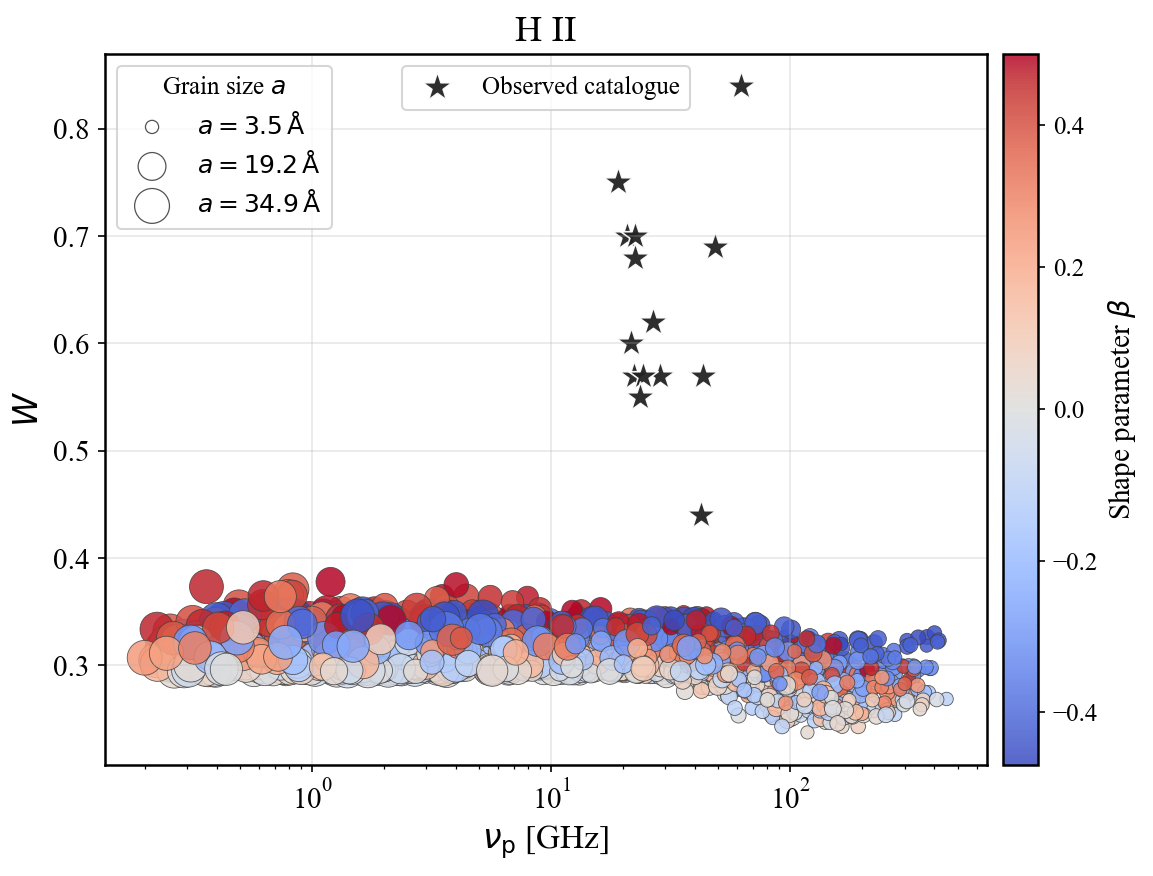

In [14]:
import matplotlib.colors as mcolors

Num=2000

grain_sizes = HII_params_tumbling[:Num, -2]  # typically the sampled grain size a
beta_values = HII_params_tumbling[:Num, -1]   # typically the shape parameter beta

size_min = grain_sizes.min()
size_max = grain_sizes.max()

size_span = size_max - size_min if size_max > size_min else 1.0

size_min_area = 40.0
size_max_area = 280.0

def _marker_area(values):
    values = np.asarray(values)
    fraction = (values - size_min) / size_span
    scaled = np.clip(fraction, 0.0, 1.0) ** 0.8  # soften the dynamic range
    return size_min_area + (size_max_area - size_min_area) * scaled

marker_sizes = _marker_area(grain_sizes)

if np.any(beta_values < 0) and np.any(beta_values > 0):
    norm = mcolors.TwoSlopeNorm(vmin=beta_values.min(), vcenter=0.0, vmax=beta_values.max())
else:
    norm = mcolors.Normalize(vmin=beta_values.min(), vmax=beta_values.max())

fig, ax = plt.subplots(figsize=(8, 6))

scatter = ax.scatter(
    HII_features_tumbling[:Num, 0],
    HII_features_tumbling[:Num, 1],
    c=beta_values,
    cmap="coolwarm",
    norm=norm,
    s=marker_sizes,
    alpha=0.85,
    edgecolors="0.25",
    linewidth=0.4
)

# scatter_no_tumbling = ax.scatter(
#     HII_features_no_tumbling[:Num, 0],
#     HII_features_no_tumbling[:Num, 1],
#     c="lightgray",
#     norm=norm,
#     s=marker_sizes,
#     alpha=0.85,
#     edgecolors="0.25",
#     linewidth=0.4
# )

obs_handle = ax.scatter(
    HII_catalogue[:, 0],
    HII_catalogue[:, 1],
    marker="*",
    s=220,
    c="#222222",
    edgecolors="white",
    linewidth=0.8,
    alpha=0.95,
    label="Observed catalogue"
)

ax.set_xlabel(r"$\nu_{\rm p}$ [GHz]", fontsize=16)
ax.set_ylabel(r"$W$", fontsize=16)
ax.set_xscale("log")
ax.grid(True, alpha=0.3)
ax.tick_params(axis="both", which="both", labelsize=14)

cbar = plt.colorbar(scatter, ax=ax, pad=0.015)
cbar.set_label(r"Shape parameter $\beta$", fontsize=14)
cbar.ax.tick_params(labelsize=12)

size_labels = np.linspace(size_min, size_max, 3)
size_handles = [
    ax.scatter([], [], s=_marker_area(val), facecolors="none", edgecolors="0.25", linewidth=0.6, alpha=0.9,
               label=fr"$a = {val*1e8:.1f}\,\mathrm{{\AA}}$")
    for val in size_labels
]

legend1 = ax.legend(
    handles=size_handles,
    title=r"Grain size $a$",
    loc="upper left",
    frameon=True,
    fontsize=12,
    title_fontsize=12
)
ax.add_artist(legend1)

legend2 = ax.legend([obs_handle], ["Observed catalogue"], loc="upper center", frameon=True, fontsize=12)

ax.set_title("H II", fontsize=18)
plt.savefig("Hii_catalogue_single.pdf")


plt.tight_layout()
plt.show()

In [15]:
# X=HII_params_no_tumbling
import copy

# Get indices where peak frequencies are larger than 5GHz.
X = copy.deepcopy(HII_params_tumbling)
Y= copy.deepcopy(HII_features_tumbling)

mask = (Y[:, 0] > 10) & (Y[:, 0] < 100)
idx = np.where(mask)[0]
print(f"Selected {len(idx)} samples out of {X.shape[0]} based on peak frequency criteria.")

X=X[idx, :]
Y=Y[idx, :]

Num=5000
X=X[:Num, :]
Y=Y[:Num, :]

from mcpost import gsa_pipeline
# from gsa_pipeline import gsa_pipeline
# # Reload the module to get latest changes
# import importlib
# importlib.reload(sys.modules['gsa_pipeline'])
# from gsa_pipeline import gsa_pipeline


# Your arrays
# X: (N_samples, N_params)
# Y: (N_samples, 2)  # columns: [peak_frequency, width]
param_names = ["nh","T","Chi","xh","xC","y", "dipole", "a","beta"]  # adjust to your order

out = gsa_pipeline(
    X, Y,
    feature_names=["nu_peak", "width"],
    param_names=param_names,
    scaler="standard",            # try "minmax" or None as well
    kernel_kind="rbf",             # try "rbf", "matern32", "matern52", "rq"
    ard=True,
    length_scale_init=1.0,        # or np.ones(d_kept) after dropping consts (handled internally)
    enable_perm=True,
    enable_gp=True,
    enable_sobol=True,
    make_pdp=True,
    N_sobol=1024,                 # increase for tighter Sobol CIs
    drop_const_atol=0.0,
    topk_pdp=3,
    pdp_prefix="pdp_demo",
    gp_random_state=0,
)

table_peak  = out["results"]["nu_peak"]["table"]
table_width = out["results"]["width"]["table"]

Selected 37777 samples out of 100000 based on peak frequency criteria.


In [16]:
from mcpost import sensitivity_table_to_latex

In [17]:
print(sensitivity_table_to_latex(table_peak, feature_label="peak"))

\begin{tabular}{llrrrrrrrrrr}
\toprule
Feature & Parameter & MI & dCor & PermMean & PermStd & S1 & S1_conf & ST & ST_conf & 1/ARD_LS & AggRank \\
\midrule
\multirow{8}{*}{peak} & a & 0.449 & 0.581 & 0.000 & 0.000 & 0.885 & 0.080 & 0.964 & 0.069 & 0.862 & 1.800 \\
 & nh & 0.009 & 0.052 & 0.002 & 0.009 & 0.020 & 0.026 & 0.088 & 0.021 & 4.121 & 2.200 \\
 & dipole & 0.006 & 0.028 & 0.007 & 0.007 & -0.000 & 0.002 & 0.000 & 0.000 & 0.052 & 4.000 \\
 & Chi & 0.000 & 0.033 & -0.009 & 0.007 & 0.014 & 0.013 & 0.028 & 0.005 & 0.399 & 4.800 \\
 & beta & 0.000 & 0.027 & -0.000 & 0.006 & 0.004 & 0.012 & 0.028 & 0.005 & 0.301 & 5.000 \\
 & T & 0.017 & 0.023 & -0.005 & 0.007 & 0.001 & 0.002 & 0.001 & 0.000 & 0.022 & 5.200 \\
 & xC & 0.000 & 0.018 & 0.004 & 0.005 & 0.000 & 0.000 & 0.000 & 0.000 & 0.010 & 6.300 \\
 & xh & 0.003 & 0.015 & -0.003 & 0.007 & -0.000 & 0.000 & 0.000 & 0.000 & 0.010 & 6.700 \\
\bottomrule
\end{tabular}



In [18]:
print(sensitivity_table_to_latex(table_width, feature_label="width"))

\begin{tabular}{llrrrrrrrrrr}
\toprule
Feature & Parameter & MI & dCor & PermMean & PermStd & S1 & S1_conf & ST & ST_conf & 1/ARD_LS & AggRank \\
\midrule
\multirow{8}{*}{width} & beta & 0.871 & 0.414 & 1.365 & 0.043 & 0.543 & 0.064 & 0.658 & 0.071 & 0.574 & 1.400 \\
 & a & 0.142 & 0.305 & 0.000 & 0.000 & 0.228 & 0.064 & 0.434 & 0.056 & 0.929 & 2.800 \\
 & nh & 0.042 & 0.098 & 0.047 & 0.007 & 0.005 & 0.038 & 0.139 & 0.020 & 6.041 & 3.000 \\
 & Chi & 0.017 & 0.129 & 0.048 & 0.008 & 0.008 & 0.024 & 0.075 & 0.017 & 0.526 & 3.600 \\
 & dipole & 0.040 & 0.102 & 0.018 & 0.005 & 0.009 & 0.019 & 0.044 & 0.009 & 0.235 & 4.400 \\
 & xC & 0.000 & 0.026 & 0.002 & 0.002 & -0.000 & 0.000 & 0.000 & 0.000 & 0.010 & 6.600 \\
 & T & 0.000 & 0.016 & -0.002 & 0.002 & -0.001 & 0.002 & 0.001 & 0.000 & 0.030 & 7.100 \\
 & xh & 0.000 & 0.021 & -0.001 & 0.003 & 0.000 & 0.000 & 0.000 & 0.000 & 0.010 & 7.100 \\
\bottomrule
\end{tabular}

